# Forecasting a chandler's order book

**Silent Ramihel Limited** — a walkthrough of the synthetic demand demo.

This notebook is the long form of the README. It loads the seeded order book, shows why the desk calendar and the vessel lineup both show up in demand, and reads the holdout that `make train` already scored. It does not refit the full backtest.

**Everything quantitative on this page is synthetic.** The generator is deterministic (`SEED = 42`). Nothing here is a statistic from a port or a client.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from chandlery_forecast.config import CATEGORY_LABELS, MODEL_LABELS, UNIT_PRICES_USD, UNITS
from chandlery_forecast.generate import load_book
from chandlery_forecast.inventory import sigma_path, suggest_order
from chandlery_forecast.paths import BUNDLE_PATH, FIGURES_DIR, REPORTS_DIR

book = load_book()
metrics = pd.read_csv(REPORTS_DIR / "metrics.csv")
by_category = pd.read_csv(REPORTS_DIR / "metrics_by_category.csv")
print(book.metadata["disclaimer"])
print(
    f"Seed {book.metadata['seed']}, {book.metadata['start']} to {book.metadata['end']}: "
    f"{book.metadata['n_calls']:,} calls, {book.metadata['n_orders']:,} orders, "
    f"{book.metadata['n_demand_rows']:,} daily rows."
)

Synthetic data generated for demonstration. Not measurements from any port, vessel, or client.
Seed 42, 2022-01-01 to 2026-09-30: 34,315 calls, 67,963 orders, 34,680 daily rows.


## What is being forecast

Each row of `daily_demand` is one port, one category, one day. The categories are the chandler's books: provisions (kg), fresh water (m³), lubricants (litres), deck and engine stores (units), and safety equipment (units).

Demand on a day is the sum of requisitions booked that day, plus a small walk-in baseline, times a port-level shock. A requisition is booked on the arrival date unless the desk is closed (Sunday or a public holiday), in which case it moves to the next open day. That rule is why Monday carries Sunday's ships.

In [2]:
calls = book.vessel_calls
print("Vessel calls")
display(calls.head(3))
print("Daily demand")
display(book.daily_demand.head(3))
summary = (
    book.daily_demand.groupby(["port", "category"])["demand"]
    .agg(mean="mean", p90=lambda s: s.quantile(0.9))
    .round(1)
)
summary

Vessel calls


,call_id,port,country,arrival_date,order_date,vessel_type,dwt,crew,passengers,stay_days,voyage_days
0,C000001,Dar es Salaam,Tanzania,2022-01-01,2022-01-03,container,54668.0,15,0,1,21
1,C000002,Dar es Salaam,Tanzania,2022-01-01,2022-01-03,container,28106.0,20,0,1,49
2,C000003,Dar es Salaam,Tanzania,2022-01-01,2022-01-03,container,29732.0,22,0,1,25


Daily demand


,date,port,category,unit,demand,vessel_qty,baseline,n_vessel_orders
0,2022-01-01,Dar es Salaam,deck_engine_stores,units,0.1,0.0,0.14,0
1,2022-01-02,Dar es Salaam,deck_engine_stores,units,0.1,0.0,0.14,0
2,2022-01-03,Dar es Salaam,deck_engine_stores,units,34.9,33.7,0.91,3


mean      p90
port          category                           
Dar es Salaam deck_engine_stores     9.9     27.4
              fresh_water          164.1    394.2
              lubricants          3247.9   9028.8
              provisions          3053.7   6912.5
              safety_equipment       3.0     10.3
Djibouti      deck_engine_stores    12.6     30.6
              fresh_water          212.3    484.4
              lubricants          4911.5  12598.2
              provisions          3916.8   8281.2
              safety_equipment       3.8     11.9
Durban        deck_engine_stores    15.1     35.0
              fresh_water          252.0    543.1
              lubricants          4799.4  12340.4
              provisions          4627.6   9701.9
              safety_equipment       4.2     13.2
Mombasa       deck_engine_stores    16.5     39.1
              fresh_water          302.3    654.6
              lubricants          4618.3  11416.5
              provisions          5635.8  12318.8
              safety_equipment       5.2     15.8

## Two patterns worth seeing before any model

The weekday chart compares the day a ship arrives with the day the requisition hits the desk. Sunday bookings go to zero. Monday takes them.

The scatter is Mombasa provisions against crew booked that day. They move together, and they are not the same thing: the model never sees how many days of stores the master will ask for, nor whether the ship buys here at all.

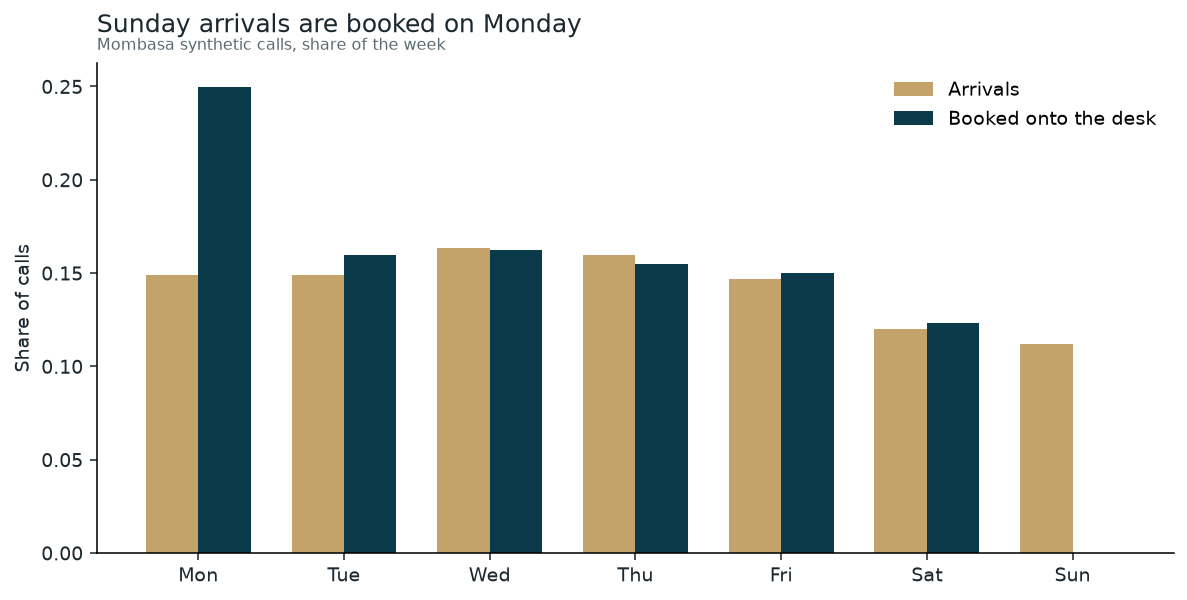

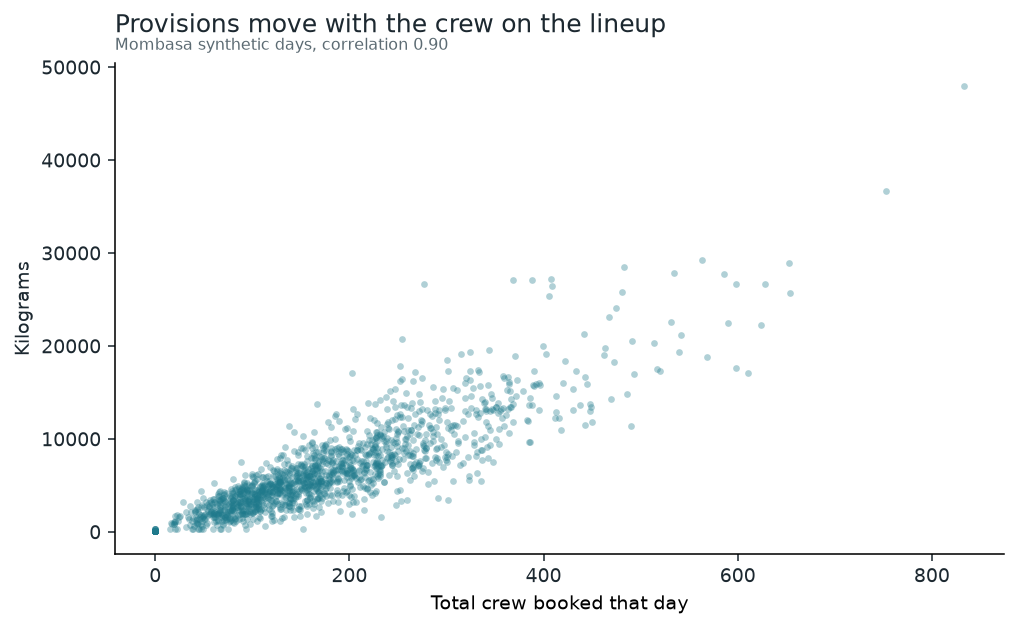

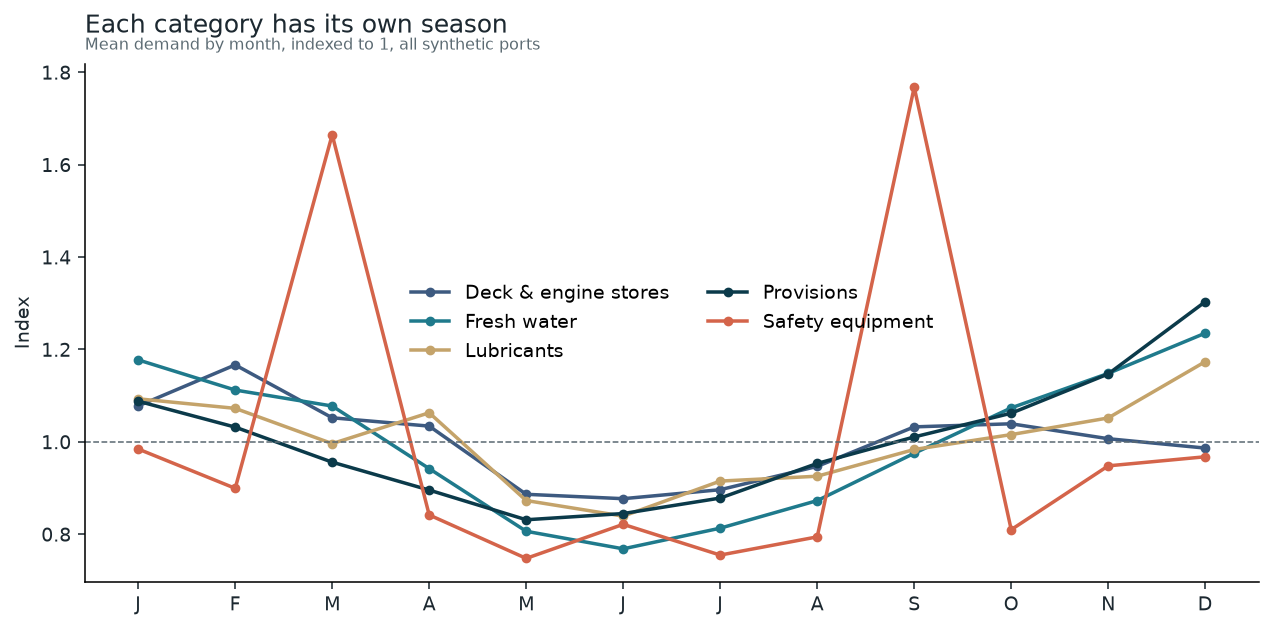

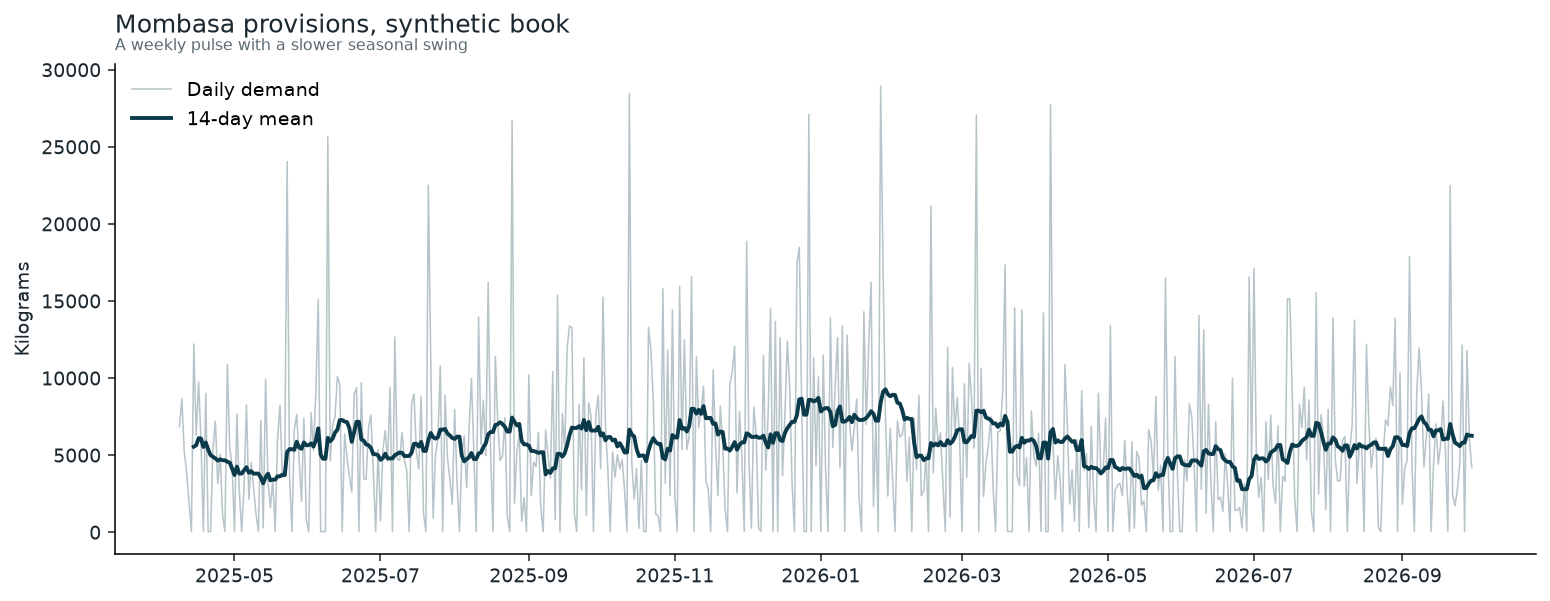

In [3]:
display(Image(filename=str(FIGURES_DIR / "weekday_booking_shift.png")))
display(Image(filename=str(FIGURES_DIR / "lineup_vs_provisions.png")))
display(Image(filename=str(FIGURES_DIR / "monthly_profile.png")))
display(Image(filename=str(FIGURES_DIR / "demand_timeline.png")))

## Models and the cutoff

Five forecasts are on the same origins.

- **Seasonal naive** repeats the last week.
- **Holt-Winters** is an additive weekly smoother, refit on each series at each origin.
- **Fourier ridge** is linear: lags, rolling statistics, calendar Fourier terms, port, and category. No lineup.
- **Gradient boosting** is the same information, fit with histogram gradient boosting on `log1p` demand.
- **Gradient boosting + lineup** adds the target day's calls, crew, deadweight, and type mix.

Regression models are fit only on targets on or before 31 Mar 2026. The scored origins start that morning and step forward 14 days. A log model under-predicts a right-skewed mean, so each category is rescaled by a multiplier estimated on the last 90 training days and applied after the refit. The purchase quantity is a mean, not a median.

WAPE below is value-weighted with the synthetic basket prices, so a kilogram error and a litre error are not added raw.

In [4]:
prices = pd.Series(UNIT_PRICES_USD, name="usd_per_unit")
prices.index = prices.index.map(CATEGORY_LABELS)
display(prices.to_frame().assign(unit=[UNITS[k] for k in UNIT_PRICES_USD]))

view = metrics.copy()
view["model"] = view["model"].map(MODEL_LABELS)
view["wape_pct"] = (view["wape"] * 100).round(1)
view["mase"] = view["mase"].round(2)
primary = view.loc[view["horizon"] == 14, ["model", "level", "wape_pct", "mae", "rmse", "mase"]]
primary = primary.rename(columns={"wape_pct": "WAPE %", "mae": "MAE (USD)", "rmse": "RMSE (USD)"})
primary.sort_values(["level", "WAPE %"])

,usd_per_unit,unit
Provisions,2.35,kg
Fresh water,12.00,m3
Lubricants,3.40,L
Deck & engine stores,55.00,units
Safety equipment,95.00,units


,model,level,WAPE %,MAE (USD),RMSE (USD),mase
5,Gradient boosting + lineup,daily,44.1,2398.788498,5543.022401,0.45
6,Fourier ridge,daily,62.0,3370.520117,7698.584605,0.65
7,Gradient boosting,daily,66.7,3626.994152,7964.312627,0.70
8,Holt-Winters (weekly),daily,68.9,3746.279671,7680.266017,0.72
9,Seasonal naive (7-day),daily,90.6,4925.974618,10804.857160,0.95
20,Gradient boosting + lineup,horizon_total,15.5,11776.272649,22344.500171,NaN
21,Holt-Winters (weekly),horizon_total,21.0,15997.160515,30490.363922,NaN
22,Gradient boosting,horizon_total,23.8,18110.864397,35363.408724,NaN
23,Fourier ridge,horizon_total,27.1,20654.847074,40531.031726,NaN
24,Seasonal naive (7-day),horizon_total,32.0,24388.619562,48500.172718,NaN


Daily WAPE looks large next to the 14-day total because a fortnight lets misses on either side of the mean cancel. The order the chandler places is the total. The lineup model is the lowest error on both cuts.

Within a category the same ordering holds, and safety equipment remains the noisy book. Native-unit WAPE, 14-day totals:

In [5]:
cat = by_category.loc[by_category["horizon"] == 14, ["model", "category", "total_wape", "daily_wape"]].copy()
cat["model"] = cat["model"].map(MODEL_LABELS)
cat["category"] = cat["category"].map(CATEGORY_LABELS)
totals = cat.pivot(index="category", columns="model", values="total_wape") * 100
totals.round(1)

model,Fourier ridge,Gradient boosting,Gradient boosting + lineup,Holt-Winters (weekly),Seasonal naive (7-day)
category,,,,,
Deck & engine stores,20.4,21.5,16.8,21.2,32.6
Fresh water,19.8,21.4,14.0,20.9,25.6
Lubricants,36.7,28.8,19.5,24.7,39.9
Provisions,15.1,17.2,9.5,15.0,20.9
Safety equipment,37.0,24.8,24.2,38.6,65.2


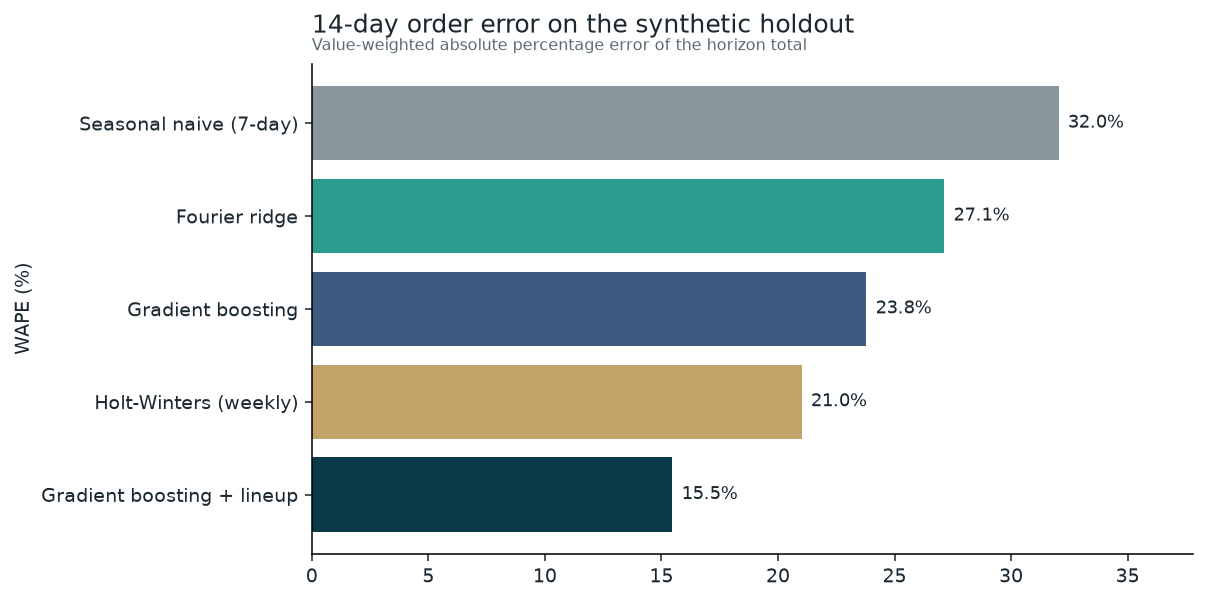

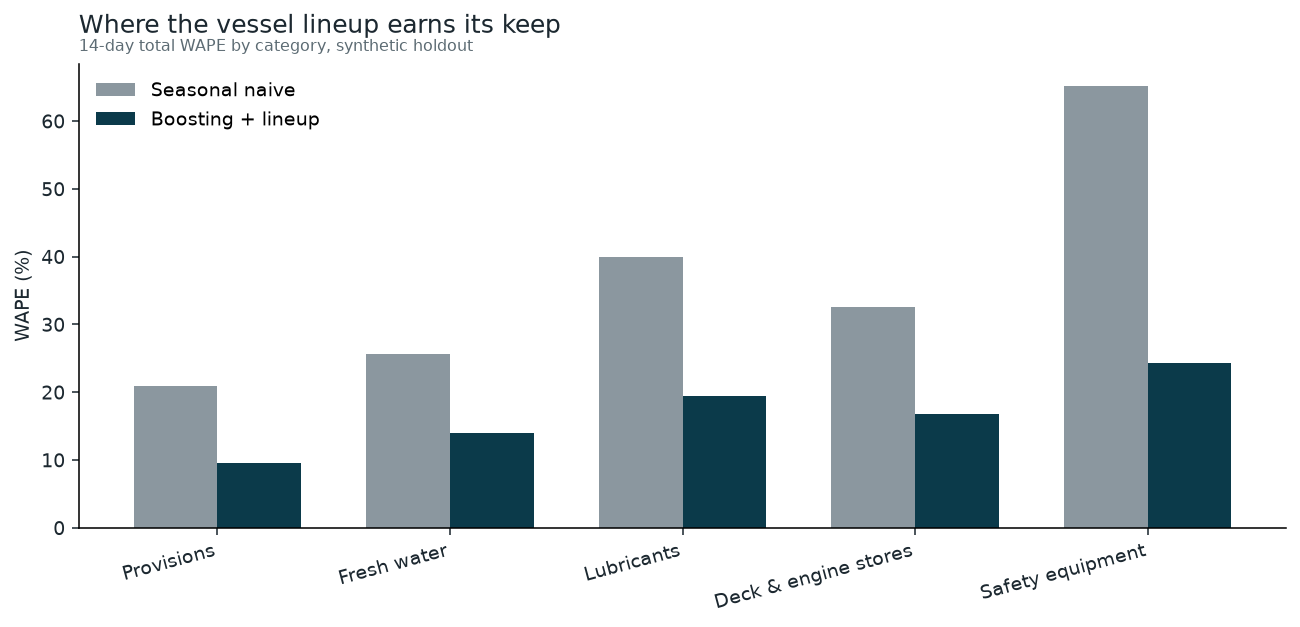

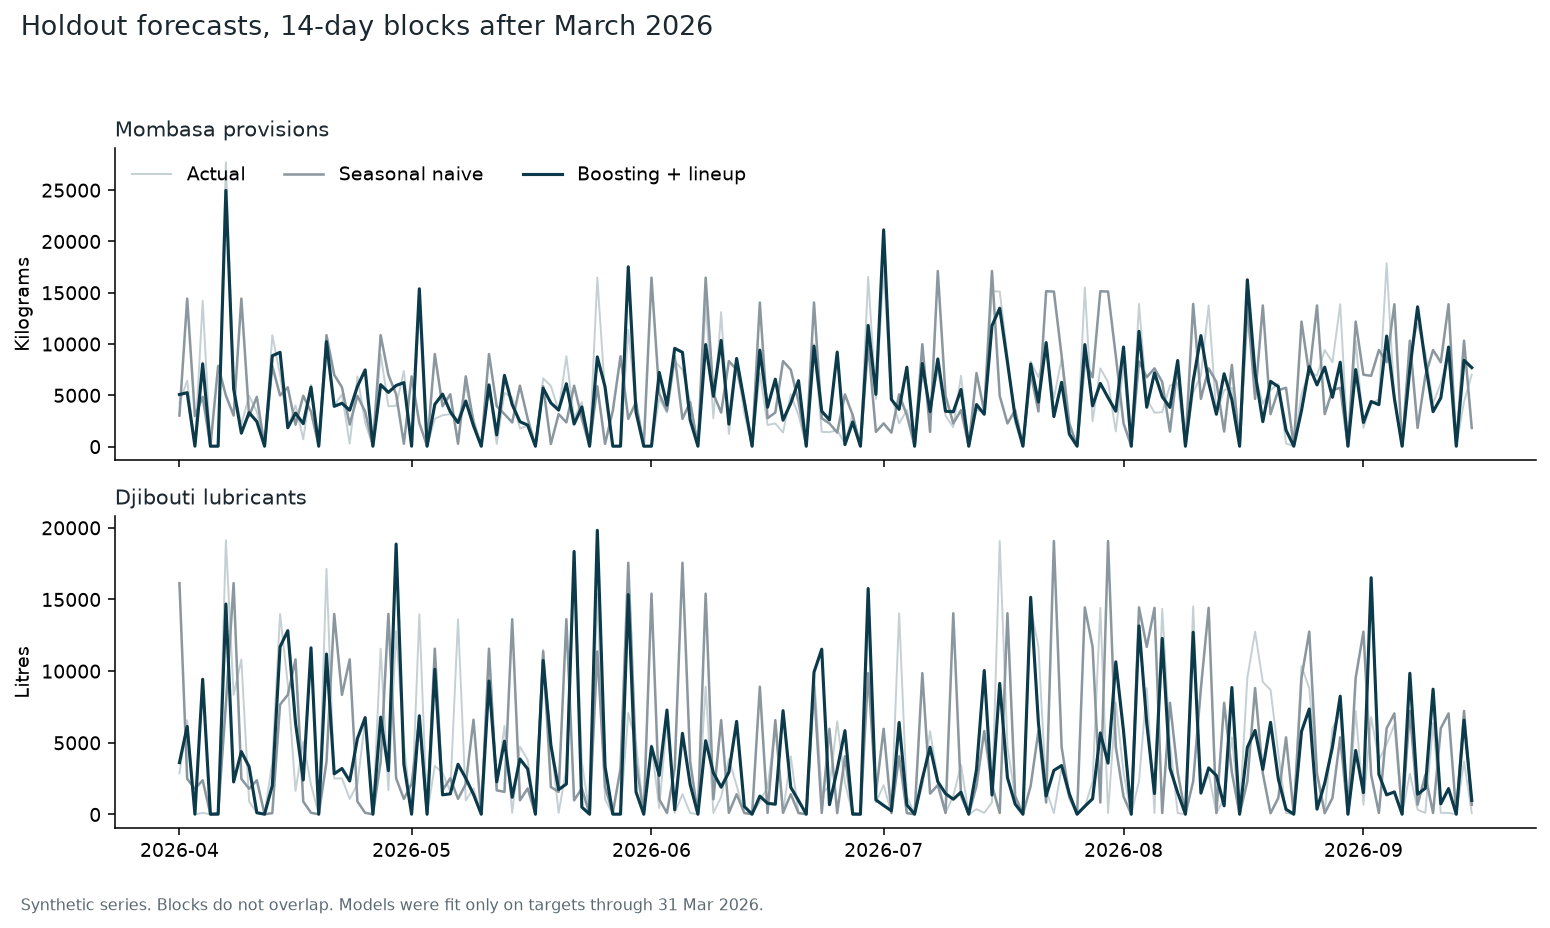

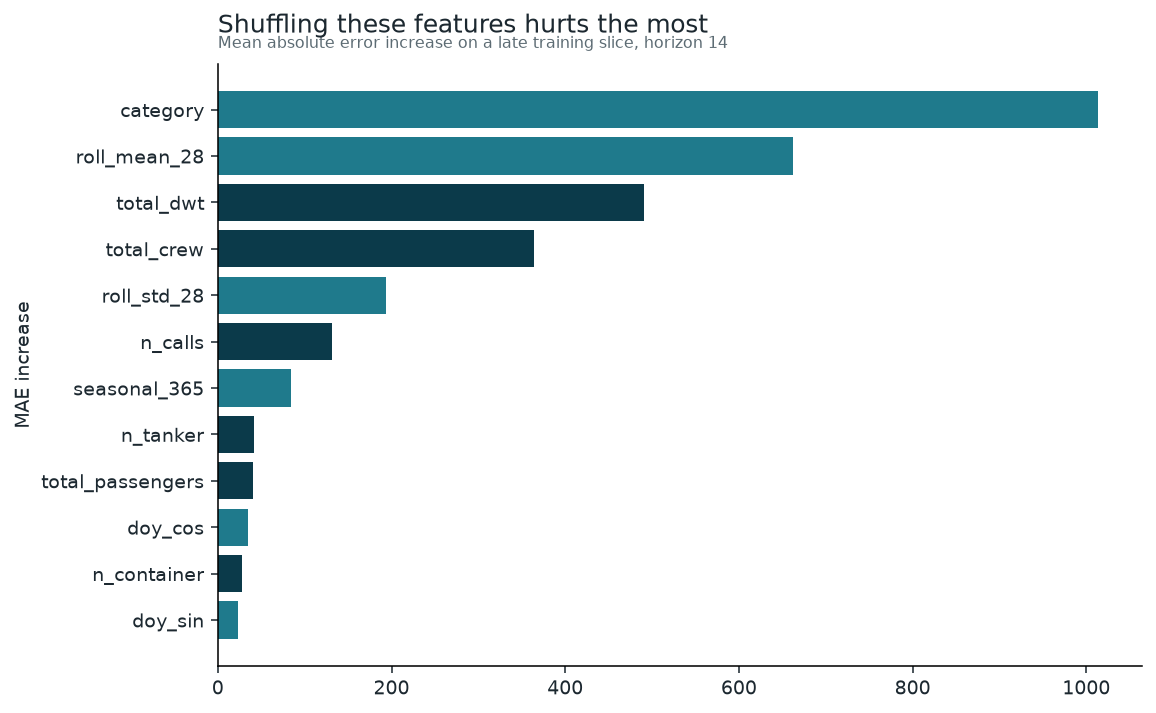

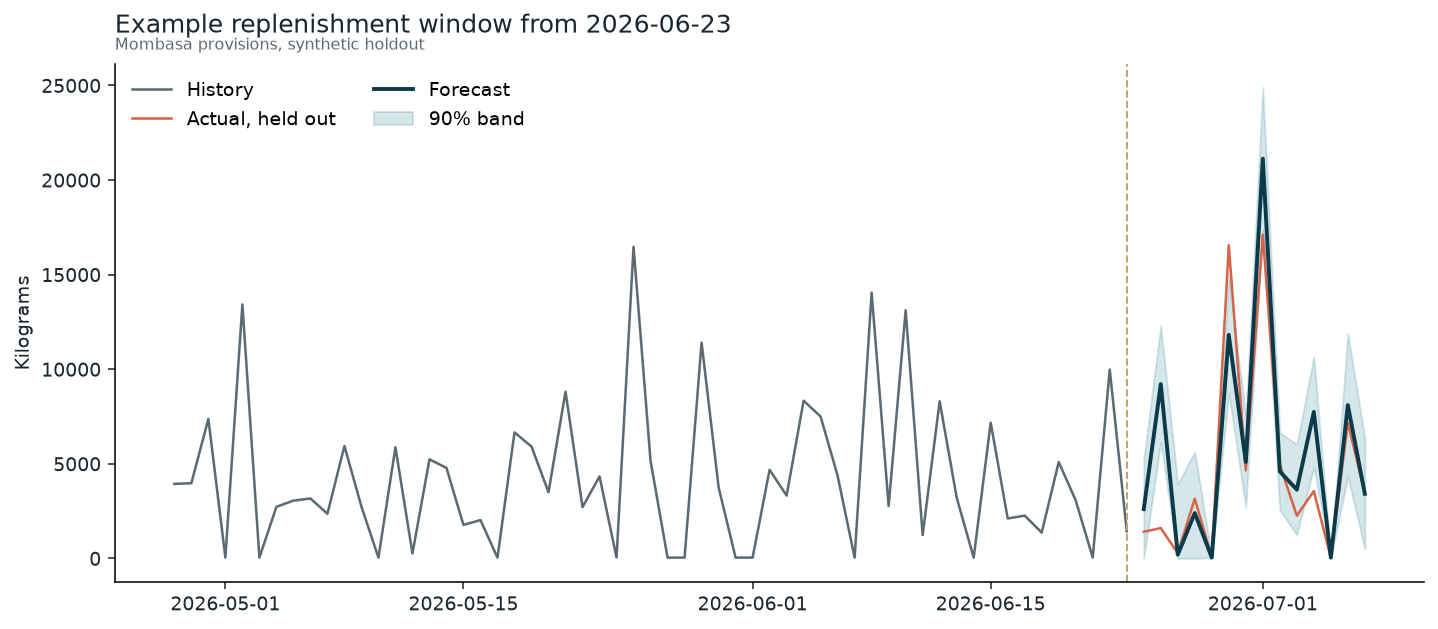

In [6]:
display(Image(filename=str(FIGURES_DIR / "model_comparison.png")))
display(Image(filename=str(FIGURES_DIR / "wape_by_category.png")))
display(Image(filename=str(FIGURES_DIR / "backtest_overlay.png")))
display(Image(filename=str(FIGURES_DIR / "feature_importance.png")))
display(Image(filename=str(FIGURES_DIR / "replenishment_example.png")))

## One suggested order

The app does this for any port and category. Here the origin is 1 Sep 2026, which is after the cutoff, for Mombasa provisions over a 14-day review cycle and a 2-day lead time. On-hand stock is set to 45% of the trailing 14 days, the same default the app uses.

The order covers lead time plus the review cycle. Safety stock is `z` times the backtest residual of the cover window, with a factor for the fact that daily errors move together.

In [7]:
import joblib

bundle = joblib.load(BUNDLE_PATH)
model = bundle["model"]
origin = pd.Timestamp("2026-09-01")
port, category = "Mombasa", "provisions"
lead, horizon = 2, 14
cover = lead + horizon

from chandlery_forecast.features import build_forecast_frame

frame = build_forecast_frame(
    book.daily_demand, book.lineup, book.holidays, origin, cover, ports=[port], categories=[category]
).sort_values("horizon")
forecast = model.predict(frame)
sigma = sigma_path(bundle["residual_std"][category], cover, fallback=1.0)
history = book.daily_demand.query("port == @port and category == @category and date <= @origin").tail(14)
on_hand = round(float(history["demand"].sum()) * 0.45, 1)
suggestion = suggest_order(
    daily_forecast=forecast,
    sigma_by_step=sigma,
    inflation=float(bundle["inflation"][category]),
    on_hand=on_hand,
    inbound=0.0,
    lead_time_days=lead,
    service_level=0.95,
    unit=UNITS[category],
    unit_price_usd=UNIT_PRICES_USD[category],
)
print(suggestion.note)
print(f"On hand: {on_hand:,.0f} {suggestion.unit}")
print(f"Expected demand over {suggestion.cover_days} days: {suggestion.expected_demand:,.0f} {suggestion.unit}")
print(f"Safety stock: {suggestion.safety_stock:,.0f} {suggestion.unit}")
print(f"Suggested order: {suggestion.suggested_qty:,.0f} {suggestion.unit}")
print(f"Indicative value at the synthetic price: USD {suggestion.indicative_value_usd:,.0f}")
pd.DataFrame({"date": frame["target_date"].dt.date, "forecast": forecast.round(1), "calls": frame["n_calls"], "crew": frame["total_crew"]})

Cover 16 days (2 days of lead time + 14 days until the next review) at a 95% service level.
On hand: 35,642 kg
Expected demand over 16 days: 97,891 kg
Safety stock: 11,649 kg
Suggested order: 73,897 kg
Indicative value at the synthetic price: USD 173,659


,date,forecast,calls,crew
0,2026-09-02,4398.7,7.0,134.0
1,2026-09-03,4086.9,4.0,129.0
2,2026-09-04,10775.2,7.0,252.0
3,2026-09-05,4699.4,6.0,129.0
4,2026-09-06,42.9,0.0,0.0
5,2026-09-07,7555.7,12.0,228.0
6,2026-09-08,13629.2,9.0,317.0
7,2026-09-09,8163.7,11.0,243.0
8,2026-09-10,3409.4,5.0,100.0
9,2026-09-11,4745.5,6.0,131.0


## What a real engagement would change

Replace the generator with invoices and the pre-arrival notices the agent already receives. Keep the cutoff, the rolling origins, and an error measured on the order value rather than on a shuffled row. The live lineup will be wrong about ships that slip a day; that miss is not in this synthetic book, and it belongs in the residual of a production model.

Built by Silent Ramihel Limited · silentramihellimited@gmail.com